# 勘误 Motolinia(2021)

*Electoral Accountability and Particularistic Legislation: Evidence from an Electoral Reform in Mexico*

## 目录

- [1. 原文主张与勘误对象](#section-1)
- [2. 原作者数据](#section-2)
- [3. 基准复现](#section-3)
- [4. 勘误：H2 末年估计的独立识别](#section-4)
- [5. 补充分析：短期连任组与限制连任组](#section-5)

**勘误结论**：原文 H1/H3 的点估计可复现；H2 末年子样本中的双重差分处理项与州和年月固定效应项完全共线。短期连任组与限制连任组补充比较的点估计为负。

**运行**：使用 Python 3.13，在已有或新建环境中按仓库根目录的 [`requirements.txt`](../requirements.txt) 安装依赖（在仓库根目录执行 `python -m pip install -r requirements.txt`）。选择同一环境作为 notebook 内核，将内核工作目录设为仓库根目录或本 notebook 所在文件夹，然后重启内核并运行所有单元。第 2 节会自动下载缺少的数据文件并校验 SHA-256。

**复现**：沿用作者已经估计的主题份额，不重新训练 CTM。Python 代码翻译自作者提供的 Stata 代码；

<a id="section-1"></a>

## 1. 原文主张与勘误对象

原文研究问题：在政党主导体制下，连续连任机会是否使议员更关注可向特定地区或群体提供利益的议题（定向立法）？因变量是**会议中定向立法的主题份额**。

原文的三个假设：H1 关注长期连任组相对限制连任组的总体变化；H2 关注这种变化是否在临近选举时更大；H3 关注长期连任组相对短期连任组的差异。

下列页码以期刊印刷版为准。

| 原文位置 | 作者比较或论断 | 本 notebook 检查    |
|---|---|------------------|
| p.108，Table 2 | 长期连任组与限制连任组，H1 | 与原文相同            |
| p.109，Figure 5 | H1 的处理前切点检查 | 与原文相同               |
| p.110，Figure 6 | 不同选举周期阶段的估计，H2 | 勘误末年估计    |
| p.111，Table 3 | 长期连任组与短期连任组，H3 | 与原文相同               |
| p.110，Figure 7 | H3 的处理前切点检查 | 与原文相同               |
| 我们的补充比较 | 短期连任组与限制连任组 | 重估 |

<a id="section-2"></a>

## 2. 原作者数据

资料来源：[Harvard Dataverse V1](https://doi.org/10.7910/DVN/NOMC0H)。

下方单元格先检查 `原作者文件/`，本地已有的文件直接校验，缺少的文件从 Dataverse 下载。项目目录无法写入时，单元格会显示实际使用的后备数据目录，后续分析也从该目录读取。若两种方法都不行，可手动下载。

| 原作者文件 | Dataverse 文件 ID | 用途 |
|---|---:|---|
| `allres.csv` | 3892153，下载参数 `format=original` | 完整会议级回归数据，含 450 个主题份额 |
| `replication_analysis.do` | 3892146 | 正文回归与图表 |
| `replication_appendix.do` | 3892135 | 作者附录分析 |
| `replication_cleaning_CTM.R` | 3892151 | 作者文本处理、主题模型、分组与结果汇总 |
| `particularistic.csv` | 3892157，下载参数 `format=original` | 作者归为定向立法的 54 个主题编号 |

In [24]:
from pathlib import Path
from itertools import product
from functools import lru_cache
import re
import numpy as np
import pandas as pd
from scipy.linalg import qr
from scipy.stats import t as student_t
import statsmodels.api as sm
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from threadpoolctl import threadpool_limits

# 避免小矩阵运算被过多 BLAS 线程拖慢；不修改系统环境。
blas_limit = threadpool_limits(limits=1)

def find_root():
    for p in [Path.cwd(), *Path.cwd().parents]:
        for candidate in [p, p / 'Motolinia(2021)', p / '读论文' / 'Motolinia(2021)']:
            if (candidate / '勘误-zh.ipynb').is_file():
                return candidate
    raise FileNotFoundError('请在 Motolinia(2021) 目录中打开 notebook，或将内核工作目录切换至该目录。')

ROOT = find_root()
ORIGINAL = ROOT / '原作者文件'
pd.set_option('display.max_columns', 12)
pd.set_option('display.precision', 6)
plt.rcParams.update({'font.family': ['Times New Roman', 'SimSun'], 'mathtext.fontset': 'stix',
                     'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titlesize': 15,
                     'axes.labelsize': 12, 'xtick.labelsize': 11, 'ytick.labelsize': 11})
COLORS = {'long': '#7CB6D3', 'short': '#8B1E2D', 'none': '#222222', 'muted': '#70869B'}

In [25]:
import hashlib
import shutil
from tempfile import NamedTemporaryFile, gettempdir
from urllib.request import Request, urlopen

# Harvard Dataverse V1.0, DOI: 10.7910/DVN/NOMC0H
SOURCE_FILES = {
    'allres.csv': (3892153,
        '7b9d34c7fa32501435e5a3f3bc7b1ea9262fb321aa504c038aa652beded798aa'),
    'replication_analysis.do': (3892146,
        '074ebfd19d05c4d30c16f4118d820b929112be893c976288199bfe31f9725c54'),
    'replication_appendix.do': (3892135,
        'df377639185abde3bf226417b9b8ca7342859929fc2f0f700f8302682f6e1930'),
    'replication_cleaning_CTM.R': (3892151,
        '0170446dbce39b8985a37f616521637ab234ab514a5cc353b863d84c5ba10b6e'),
    'particularistic.csv': (3892157,
        '100b6b85ea03f16aa6a62dbbfa4d4c661cceef0f99bb115fb9bd1a228d6124f2'),
}


def verify_sha256(path, filename, expected):
    with path.open('rb') as source:
        actual = hashlib.file_digest(source, 'sha256').hexdigest()
    if actual != expected:
        raise ValueError(f'{filename} 的 SHA-256 不匹配：预期 {expected}，实际 {actual}')
    return actual


def prepare_data_directory(directory):
    # 文件齐全时只读校验，只有缺少文件时才检查写权限。
    if all((directory / name).is_file() for name in SOURCE_FILES):
        return directory
    directory.mkdir(parents=True, exist_ok=True)
    with NamedTemporaryFile(dir=directory, suffix='.part'):
        pass
    return directory


project_data = ROOT / '原作者文件'
try:
    ORIGINAL = prepare_data_directory(project_data)
except PermissionError:
    cache = Path(gettempdir()) / 'motolinia-NOMC0H-v1'
    try:
        ORIGINAL = prepare_data_directory(cache)
    except PermissionError as exc:
        raise PermissionError(f'无法写入项目数据目录 {project_data} 或后备目录 {cache}') from exc
    print(f'项目目录无法写入，使用后备数据目录：{ORIGINAL}')
print('文件名\tSHA-256')
for filename, (file_id, expected) in SOURCE_FILES.items():
    target = ORIGINAL / filename
    if target.exists():
        actual = verify_sha256(target, filename, expected)
    else:
        url = f'https://dataverse.harvard.edu/api/access/datafile/{file_id}?format=original'
        request = Request(url, headers={'User-Agent': 'Mozilla/5.0 (reading papers)'})
        partial = None
        try:
            with NamedTemporaryFile(dir=ORIGINAL, suffix='.part', delete=False) as output:
                partial = Path(output.name)
                with urlopen(request, timeout=120) as response:
                    shutil.copyfileobj(response, output)
            actual = verify_sha256(partial, filename, expected)
            if target.exists():
                actual = verify_sha256(target, filename, expected)
            else:
                partial.replace(target)
        finally:
            if partial is not None:
                partial.unlink(missing_ok=True)
    print(f'{filename}\t{actual}')

文件名	SHA-256
allres.csv	7b9d34c7fa32501435e5a3f3bc7b1ea9262fb321aa504c038aa652beded798aa
replication_analysis.do	074ebfd19d05c4d30c16f4118d820b929112be893c976288199bfe31f9725c54
replication_appendix.do	df377639185abde3bf226417b9b8ca7342859929fc2f0f700f8302682f6e1930
replication_cleaning_CTM.R	0170446dbce39b8985a37f616521637ab234ab514a5cc353b863d84c5ba10b6e
particularistic.csv	100b6b85ea03f16aa6a62dbbfa4d4c661cceef0f99bb115fb9bd1a228d6124f2


### 2.1 加载数据

一行是一场议会会议；`particularistic` 是作者归为定向立法的主题份额总和，单位为 0–1 比例。

`treat4=1` 为长期连任组、`treat2=1` 为短期连任组；墨西哥城 `CdMex` 和普埃布拉 `Puebla` 的两个变量均为 0；其他比较中不适用的组被作者设为缺失值。

`reform` 沿用作者已编码的议会任期，它在不同州可能于不同时间取 1。作者 `date2` 的实际构造是 `realyear*100` 后再拼接两位月份，即 `年份*10000+月份`。下面保留这一编码以直接执行原脚本日期条件；另建正常日期用于阅读和画图。

In [26]:
raw = pd.read_csv(ORIGINAL / 'allres.csv')
assert raw.shape == (6890, 471)
data = raw.copy()
date = pd.to_datetime(data.realyear.astype(str) + ' ' + data.month,
                      format='%Y %B', errors='coerce')
data['date'] = date
data['date2'] = date.dt.year * 10000 + date.dt.month
data['month_index'] = date.dt.year * 12 + date.dt.month
data['D_long'] = data.treat4 * data.reform
data['D_short'] = data.treat2 * data.reform
data['treat42'] = np.select([data.treat4.eq(1), data.treat2.eq(1)], [1., 0.], default=np.nan)
data['D_horizon'] = data.treat42 * data.reform
topic_columns = [f'V{i}' for i in range(1, 451)]
assert set(topic_columns).issubset(data.columns)
assert data.state.nunique() == 20
display(pd.DataFrame({'字段': ['state', 'date', 'particularistic', 'treat4', 'treat2', 'reform'],
                      '缺失行数': [data[c].isna().sum() for c in
                                 ['state', 'date', 'particularistic', 'treat4', 'treat2', 'reform']]}))
display(data[['state', 'realyear', 'month', 'treat4', 'treat2', 'reform', 'particularistic']].head())

,字段,缺失行数
0,state,0
1,date,6
2,particularistic,0
3,treat4,1988
4,treat2,4077
5,reform,0


,state,realyear,month,treat4,treat2,reform,particularistic
0,Campeche,2012,October,1.0,NaN,0,0.006359
1,Campeche,2012,December,1.0,NaN,0,0.003161
2,Campeche,2012,October,1.0,NaN,0,0.047293
3,Campeche,2012,December,1.0,NaN,0,0.004786
4,Campeche,2012,October,1.0,NaN,0,0.011634


In [27]:
def group_label(row):
    if row.treat4 == 1:
        return '长期连任组'
    if row.treat2 == 1:
        return '短期连任组'
    return '限制连任组'

data['group'] = data.apply(group_label, axis=1)
group_inventory = data.groupby(['group', 'state']).agg(会议数=('state', 'size'),
                  首次记录=('date', 'min'),末次记录=('date', 'max')).reset_index()
display(group_inventory)
display(data.groupby('group').agg(州数=('state', 'nunique'), 会议数=('state', 'size')))

,group,state,会议数,首次记录,末次记录
0,短期连任组,Aguascalientes,142,2013-11-01,2017-12-01
1,短期连任组,Chihuahua,390,2013-04-01,2018-03-01
2,短期连任组,Colima,467,2012-09-01,2018-03-01
3,短期连任组,Hidalgo,197,2015-01-01,2017-11-01
4,短期连任组,Oaxaca,107,2013-01-01,2018-12-01
5,短期连任组,Zacatecas,685,2013-09-01,2018-06-01
6,长期连任组,Campeche,514,2012-10-01,2018-03-01
7,长期连任组,Chiapas,458,2012-10-01,2017-12-01
8,长期连任组,Durango,484,2013-09-01,2018-03-01
9,长期连任组,Guanajuato,249,2012-09-01,2018-03-01


,州数,会议数
group,,
短期连任组,6,1988
长期连任组,12,4077
限制连任组,2,825


### 2.2 CTM 份额如何变成因变量

作者 R 脚本使用 `stm(alldfm, K=450, seed=12345678)`，随后按分类表将 54 个主题相加。以下主题编号来自作者公开的 [`particularistic.csv`](https://dataverse.harvard.edu/api/access/datafile/3892157?format=original)，由第 2 节的下载单元格获取并校验。

In [28]:
particularistic_topics = pd.read_csv(ORIGINAL / 'particularistic.csv')['part'].tolist()
assert len(set(particularistic_topics)) == 54
rebuilt_y = raw[[f'V{i}' for i in particularistic_topics]].sum(axis=1)
max_y_gap = (rebuilt_y - raw.particularistic).abs().max()
topic_sum_gap = (raw[topic_columns].sum(axis=1) - 1).abs().max()
# 明确采用比例单位的数值容差，不要求 CSV 导出的各列逐位相等。
assert np.allclose(rebuilt_y, raw.particularistic, atol=1e-6, rtol=0)
assert np.allclose(raw[topic_columns].sum(axis=1), 1, atol=1e-5, rtol=0)
display(pd.DataFrame({'检查': ['450 个主题份额总和与 1 的最大差',
                              '54 个主题加总与原因变量的最大差'],
                      '数值': [topic_sum_gap, max_y_gap]}))

,检查,数值
0,450 个主题份额总和与 1 的最大差,1.615000e-06
1,54 个主题加总与原因变量的最大差,4.940000e-07


回归完整沿用作者 `particularistic` 列，最大汇总差约为 $4.94\times10^{-7}$ 个比例单位，450 个主题之和偏离 1 的最大值约为 $1.615\times10^{-6}$，与小量数值导出精度差异相容。

<a id="section-3"></a>

## 3. 基准复现

### 3.1 原文模型和本程序是否一致

原文模型的核心是

$$Y_{ist}=\alpha+\beta D_{st}+\mu_s+\gamma_t+\varepsilon_{ist}.$$

$\mu_s$ 为州固定效应，$\gamma_t$ 为年月固定效应；$D$ 由作者的分组 $R_s$ 和 `reform`  $T_t$ 相乘得到。

我们先核对模型，从原文件打印作者命令，并列出 Python 对照。

In [29]:
author_code = (ORIGINAL / 'replication_analysis.do').read_text(encoding='utf-8')
for marker in ['*Table 2: H1', '*Table 3: H3']:
    block = author_code[author_code.index(marker):].splitlines()
    command = next(line.strip() for line in block if line.strip().startswith('reg '))
    print(marker, '\n', command, '\n')
scope_comparison = pd.DataFrame([
    {'项目':'H1','原文位置':'Table 2, p.108','原处理项':'timb3=treat4*reform',
     'Python处理项':'D_long','样本规则':'treat4适用组，保留原NA排除'},
    {'项目':'H3','原文位置':'Table 3, p.111','原处理项':'c.treat42#c.reform',
     'Python处理项':'D_horizon','样本规则':'长期连任组与短期连任组'},
    {'项目':'H2末年','原文位置':'Figure 6, p.110','原处理项':'timb3，if timingc==1',
     'Python处理项':'D_long + 原timingc筛选','样本规则':'从.do逐条解析6条replace条件'},
    {'项目':'补充比较','原文位置':'我们新增','原处理项':'正文未报告',
     'Python处理项':'D_short','样本规则':'短期连任组与限制连任组，重新估计'}
])
display(scope_comparison)
display(pd.DataFrame([
    {'设置':'固定效应','作者':'州 + 年月','Python':'同一固定效应空间'},
    {'设置':'标准误','作者':'按州聚类','Python':'州聚类CR1，t(G−1)参考分布'},
    {'设置':'数据与因变量','作者':'allres.csv / particularistic','Python':'保留原值及处理编码'},
    {'设置':'完全共线性','作者':'Stata可自动省略冗余项','Python':'先检查残差变化与矩阵秩；未识别时不输出效应'},
    {'设置':'额外bootstrap','作者':'我们的程序','Python':'用于短期连任组补充比较'}
]))

*Table 2: H1 
 reg particularistic timb3 i.edo i.date2,robust cluster(edo) 

*Table 3: H3 
 reg particularistic c.treat42#c.reform i.edo i.date2,robust cluster(edo) 



,项目,原文位置,原处理项,Python处理项,样本规则
0,H1,"Table 2, p.108",timb3=treat4*reform,D_long,treat4适用组，保留原NA排除
1,H3,"Table 3, p.111",c.treat42#c.reform,D_horizon,长期连任组与短期连任组
2,H2末年,"Figure 6, p.110",timb3，if timingc==1,D_long + 原timingc筛选,从.do逐条解析6条replace条件
3,补充比较,我们新增,正文未报告,D_short,短期连任组与限制连任组，重新估计


,设置,作者,Python
0,固定效应,州 + 年月,同一固定效应空间
1,标准误,按州聚类,州聚类CR1，t(G−1)参考分布
2,数据与因变量,allres.csv / particularistic,保留原值及处理编码
3,完全共线性,Stata可自动省略冗余项,先检查残差变化与矩阵秩；未识别时不输出效应
4,额外bootstrap,我们的程序,用于短期连任组补充比较


### 3.2 Python 估计实现

下方用 Frisch–Waugh–Lovell 残差化估计；QR 分解仅保留固定效应的独立列；完全共线时返回“未识别”。

标准误采用州聚类 CR1，常规 p 值和 95% 区间使用 $t(G-1)$。少聚类补充推断使用零假设约束下的 Rademacher wild cluster bootstrap，枚举全部 $2^G$ 符号组合。

In [30]:
@lru_cache(None)
def sign_weights(g):
    if g > 12:
        raise ValueError('枚举 bootstrap 仅用于本 notebook 的少聚类补充比较。')
    return np.asarray(list(product([-1., 1.], repeat=g))).T

class FixedEffectsDesign:
    def __init__(self, frame):
        self.frame = frame.dropna(subset=['state', 'date2', 'particularistic']).copy()
        self.n = len(self.frame)
        self.cluster_id, self.states = pd.factorize(self.frame.state, sort=True)
        self.g = len(self.states)
        self.cluster = np.eye(self.g)[self.cluster_id]
        months, _ = pd.factorize(self.frame.date2, sort=True)
        # 全套州虚拟变量表示截距；年月变量省略一类。
        self.controls = np.column_stack([self.cluster,
                            np.eye(months.max()+1)[months, 1:]])
        q, r, piv = qr(self.controls, mode='economic', pivoting=True)
        diagonal = np.abs(np.diag(r))
        tol = max(self.controls.shape) * np.finfo(float).eps * diagonal.max()
        self.rank = int((diagonal > tol).sum())
        self.q = q[:, :self.rank]
        self.y = self.frame.particularistic.to_numpy(float)
        self.yr = self.residualize(self.y)

    def residualize(self, z):
        z = np.asarray(z, dtype=float)
        return z - self.q @ (self.q.T @ z)

    def fit(self, regressor, wild=False, return_boot=False):
        if isinstance(regressor, str):
            regressor = self.frame[regressor]
        elif isinstance(regressor, pd.Series):
            regressor = regressor.reindex(self.frame.index)
        x = np.asarray(regressor, dtype=float)
        assert len(x) == self.n and np.isfinite(x).all()
        xr = self.residualize(x)
        xx = float(xr @ xr)
        result = dict(n=self.n, states=self.g, rank_FE=self.rank,
                      rank_FE_D=self.rank + int(xx > 1e-10), residual_D_ss=xx)
        if xx <= 1e-10:
            result.update(identified=False, b=np.nan, se=np.nan, p=np.nan,
                          ci_lower=np.nan, ci_upper=np.nan, wild_p=np.nan)
            return result
        b = float(xr @ self.yr / xx)
        u = self.yr - b*xr
        correction = self.g/(self.g-1) * (self.n-1)/(self.n-self.rank-1)
        cluster_scores = self.cluster.T @ (xr*u)
        se = float(np.sqrt(correction * (cluster_scores @ cluster_scores)) / xx)
        p = float(2*student_t.sf(abs(b/se), self.g-1))
        critical = student_t.ppf(.975, self.g-1)
        result.update(identified=True, b=b, se=se, p=p,
                      ci_lower=b-critical*se, ci_upper=b+critical*se, wild_p=np.nan)
        if wild:
            # H0: beta=0；固定效应受限拟合的残差是 yr。
            weights = sign_weights(self.g)
            y_star = self.yr[:, None] * weights[self.cluster_id]
            y_star = self.residualize(y_star)
            b_star = (xr @ y_star) / xx
            u_star = y_star - xr[:, None]*b_star
            scores = self.cluster.T @ (xr[:, None]*u_star)
            se_star = np.sqrt(correction*np.sum(scores**2, axis=0)) / xx
            boot_t = np.abs(b_star/se_star)
            result['wild_p'] = float(np.mean(boot_t >= abs(b/se)-1e-12))
            if return_boot:
                result['boot_t'] = boot_t
        return result

def design_for(column, frame=data):
    return FixedEffectsDesign(frame.dropna(subset=[column]))

def result_table(records):
    table = pd.DataFrame(records).copy()
    for source, target in [('b','估计（百分点）'), ('se','聚类SE（百分点）'),
                            ('ci_lower','95%下限'), ('ci_upper','95%上限')]:
        table[target] = table[source]*100
    return table[['comparison','n','states','identified','估计（百分点）','聚类SE（百分点）',
                  '95%下限','95%上限','p','wild_p','rank_FE','rank_FE_D']].rename(
                  columns={'comparison':'比较','n':'会议数','states':'州数','identified':'独立识别',
                           'p':'常规p','wild_p':'wild bootstrap p'})

def forest(ax, records, labels, title, colors):
    for i, (r, label, color) in enumerate(zip(records, labels, colors)):
        if r['identified']:
            ax.errorbar(r['b']*100, i,
                xerr=[[100*(r['b']-r['ci_lower'])], [100*(r['ci_upper']-r['b'])]],
                fmt='o', color=color, capsize=4, markersize=7)
    ax.axvline(0, color='#555555', linestyle='--', linewidth=1)
    ax.set_yticks(range(len(labels)), labels)
    ax.set_ylim(len(labels)-.5, -.5)
    ax.set_xlabel('DID coefficient (percentage points); 95% clustered CI')
    ax.set_title(title, loc='left', pad=14)
    ax.grid(axis='x', color='#E4EAF0', linewidth=.7)

### 3.3 H1、H3 基准复现

先核对原文主要点估计与处理项的独立变化，再说明 H2 末年估计的勘误。

,比较,会议数,州数,独立识别,估计（百分点）,聚类SE（百分点）,95%下限,95%上限,常规p,wild bootstrap p,rank_FE,rank_FE_D
0,H1：长期连任组与限制连任组,4899,14,True,1.525336,0.706083,-0.000062,3.050735,0.050008,NaN,102,103
1,H3：长期连任组与短期连任组,6062,18,True,2.623266,0.518190,1.529980,3.716551,0.000096,NaN,92,93


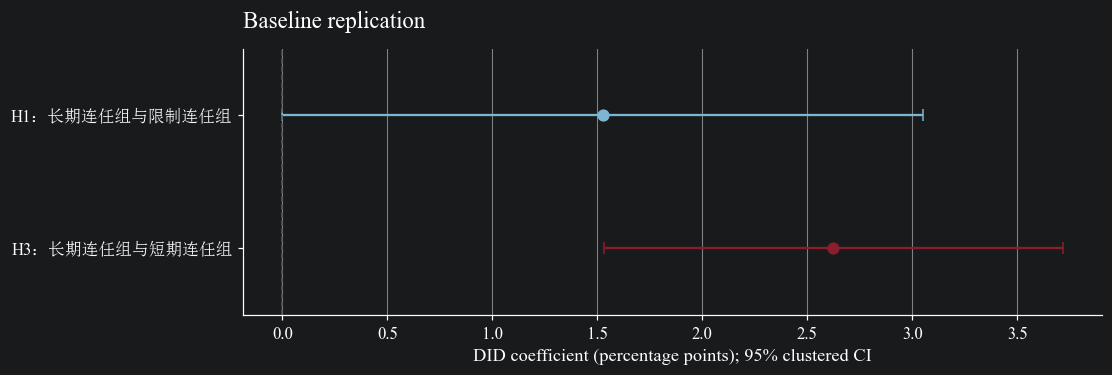

In [31]:
h1_design = design_for('D_long')
h3_design = design_for('D_horizon')
h1 = h1_design.fit('D_long'); h1['comparison'] = 'H1：长期连任组与限制连任组'
h3 = h3_design.fit('D_horizon'); h3['comparison'] = 'H3：长期连任组与短期连任组'
assert h1['n'] == 4899 and np.isclose(h1['b'], .01525336444865884)
assert h3['n'] == 6062 and np.isclose(h3['b'], .02623265672428348)
display(result_table([h1, h3]))

# 用 statsmodels 的完整 OLS + 聚类协方差交叉核对 FWL 实现。
X_check = np.column_stack([h1_design.controls, h1_design.frame.D_long])
ols_check = sm.OLS(h1_design.y, X_check).fit(cov_type='cluster',
    cov_kwds={'groups': h1_design.frame.state}, use_t=True)
assert np.isclose(ols_check.params[-1], h1['b'], atol=1e-12)
# 只检验处理系数，避免为未报告的固定效应计算标准误。
h1_contrast = ols_check.t_test(f'{ols_check.model.exog_names[-1]} = 0')
assert np.isclose(h1_contrast.sd.item(), h1['se'], atol=1e-12)
fig, ax = plt.subplots(figsize=(10, 3.3), layout='constrained')
forest(ax, [h1,h3], ['H1：长期连任组与限制连任组','H3：长期连任组与短期连任组'],
       'Baseline replication', [COLORS['long'], COLORS['short']])
plt.show()

H1 约为 **+1.53 个百分点**。按本 notebook 明确采用的 CR1 和 $t(G-1)$ 计算，精确 p 值约 **0.050008**，并不小于0.05。H3 约为 **+2.62 个百分点**。两个基准回归的系数与标准误与原文一致，处理项均有固定效应之外的独立变化。

**原文报告值对照（单位：百分点）**

| 结果 | 原文报告 | 本复现 | 对照结果 |
| --- | ---: | ---: | --- |
| H1（Table 2，p.108） | +1.53 | +1.5253 | 按原表精度取整后相同 |
| H3（Table 3，p.111） | +2.62 | +2.6233 | 按原表精度取整后相同 |
| H2 末年（Figure 6，p.110） | 约 +4.60（图上读数） | +4.5992（保留 $D$，额外省略 2016 年 6 月的月份项） | 图上读数相符，完整规格下 $\beta$ 无法单独识别 |

H1 与 H3 的原文报告值分别由原表的 0.0153 与 0.0262 乘以 100 得到。H2 的对照针对图中末期点的数值，见 4.6 节的参数化对照。

### 3.4 原文 H1/H3 的处理前检查

以下从原始 `.do` 的 `rm101` 日期条件提取各州的选举年份，再按原脚本顺序构造 12+12+9 个切点，置信区间为逐项常规 95% 区间。

,比较,切点数,常规p<0.05个数
0,H1：长期连任组与限制连任组,33,4
1,H3：长期连任组与短期连任组,33,0


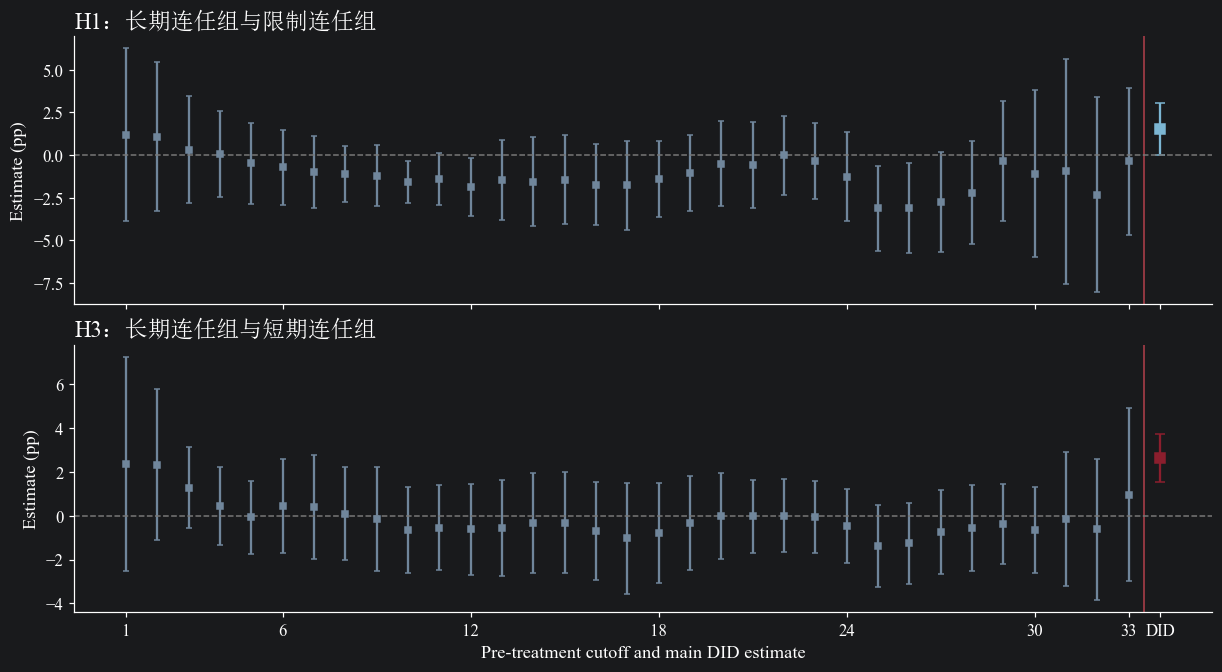

In [32]:
author_code = (ORIGINAL / 'replication_analysis.do').read_text(encoding='utf-8')
cohort = {}
for threshold, expression in re.findall(
        r'(?:gen|replace) rm10[^=]*=0 if date2<(\d+)[^&]*& \(([^\r\n]*)\)', author_code):
    for state in re.findall(r'state=="([^"]+)"', expression):
        cohort[state] = int(threshold[:4])
assert len(cohort) == 20 and cohort['Puebla'] == 2013 and cohort['CdMex'] == 2015
cutoffs = [(shift, month) for shift, count in [(2,12),(1,12),(0,9)]
                         for month in range(1,count+1)]

def placebo_checks(group_column, wild=False):
    sample = data.loc[data.reform.eq(0) & data[group_column].notna()].copy()
    design = FixedEffectsDesign(sample)
    records, draws = [], []
    for i, (shift, month) in enumerate(cutoffs, 1):
        threshold = (design.frame.state.map(cohort)-shift)*10000+month
        x = design.frame[group_column] * design.frame.date2.ge(threshold)
        r = design.fit(x, wild=wild, return_boot=wild)
        if wild:
            draws.append(r.pop('boot_t'))
        r.update(cutoff=i, cohort_shift=shift, month=month)
        records.append(r)
    table = pd.DataFrame(records)
    joint_p = np.nan
    if wild:
        # 所有切点使用同一套、同一州顺序的枚举权重，保留检验间依赖。
        observed = np.max(np.abs(table.b/table.se))
        joint_p = float(np.mean(np.max(np.vstack(draws),axis=0) >= observed-1e-12))
    return table, joint_p

pre_h1, _ = placebo_checks('treat4')
pre_h3, _ = placebo_checks('treat42')
display(pd.DataFrame({'比较':['H1：长期连任组与限制连任组','H3：长期连任组与短期连任组'],
    '切点数':[len(pre_h1),len(pre_h3)],
    '常规p<0.05个数':[(pre_h1.p<.05).sum(),(pre_h3.p<.05).sum()]}))

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True, layout='constrained')

for ax, table, did, title, color in zip(
        axes, [pre_h1, pre_h3], [h1, h3],
        ['H1：长期连任组与限制连任组', 'H3：长期连任组与短期连任组'],
        [COLORS['long'], COLORS['short']]):

    ax.errorbar(
        table.cutoff, table.b * 100,
        yerr=np.vstack([
            (table.b - table.ci_lower) * 100,
            (table.ci_upper - table.b) * 100,
        ]),
        fmt='s', ms=4, capsize=2, color=COLORS['muted'],
    )

    did_position = len(table) + 1
    ax.axvline(did_position - 0.5, color='#B2414C', linewidth=1)
    ax.errorbar(
        did_position, did['b'] * 100,
        yerr=[
            [100 * (did['b'] - did['ci_lower'])],
            [100 * (did['ci_upper'] - did['b'])],
        ],
        fmt='s', ms=6, capsize=3, color=color,
    )

    ax.axhline(0, color='#777777', linestyle='--', linewidth=1)
    ax.set_title(title, loc='left')
    ax.set_ylabel('Estimate (pp)')

axes[-1].set_xlabel('Pre-treatment cutoff and main DID estimate')
axes[-1].set_xticks(
    [1, 6, 12, 18, 24, 30, 33, 34],
    ['1', '6', '12', '18', '24', '30', '33', 'DID'],
)
plt.show()

与原文图5/7完全一致

<a id="section-4"></a>

## 4. 勘误：H2 末年估计的独立识别

按 H2 假设，三年的点估计应该递增，但 Figure 6 的三期中，t+1 的点估计低于 t，不存在单调上升。 故 H2 的唯一支持来自 t+2， 而 4.4–4.6 表明，t+2 的处理项在该样本中不可识别，因为我们发现处理项与地区+时间固定效应项完全共线，这撼动了文章根基。

### 4.1 重建作者的三个周期子样本

从 `.do` 直接提取 `timinga/timingb/timingc` 条件，对应 Figure 6 的 `Election (t)`、`t+1`、`t+2`。

In [33]:
start = author_code.index('*Figure 6: H2')
end = author_code.index('coefplot', start)
print(author_code[start:end].strip())

def original_timing_mask(name):
    clauses = re.findall(r'replace '+name+r'=1 if date2>(\d+) & date2<=(\d+) & \(([^\r\n]*)\)',
                         author_code)
    assert len(clauses) == 6
    mask = pd.Series(False, index=data.index)
    for lo, hi, expression in clauses:
        states = re.findall(r'state=="([^"]+)"', expression)
        mask |= data.date2.gt(int(lo)) & data.date2.le(int(hi)) & data.state.isin(states)
    return mask

timing = {name: original_timing_mask(name) for name in ['timinga','timingb','timingc']}
h2_records, h2_designs = [], {}
for name, label in [('timinga','Election (t)'),('timingb','t+1'),('timingc','t+2')]:
    model = FixedEffectsDesign(data.loc[timing[name] & data.D_long.notna()])
    h2_designs[name] = model
    r = model.fit('D_long');r['comparison'] = label
    h2_records.append(r)
display(result_table(h2_records))
assert h2_records[2]['n'] == 1511 and not h2_records[2]['identified']

*Figure 6: H2
local vars "particularistic"
foreach x in `vars'{
reg `x' timb3 i.edo i.date2 if timinga==1,  robust cluster(edo) 
estimate store tim_`x'
reg `x' timb3 i.edo i.date2 if timingb==1,  robust cluster(edo) 
estimate store tim2_`x'
reg `x' timb3 i.edo i.date2 if timingc==1,  robust cluster(edo) 
estimate store tim3_`x'
}


,比较,会议数,州数,独立识别,估计（百分点）,聚类SE（百分点）,95%下限,95%上限,常规p,wild bootstrap p,rank_FE,rank_FE_D
0,Election (t),1646,14,True,1.215076,1.309930,-1.614856,4.045009,0.370523,NaN,61,62
1,t+1,1877,14,True,-0.162978,1.372975,-3.129110,2.803154,0.907324,NaN,61,62
2,t+2,1511,14,False,NaN,NaN,NaN,NaN,NaN,NaN,59,59


表中 `t+2` 的系数留空，表示在保留全部固定效应空间时处理项没有独立变化。下面先解释样本，再说明为什么添加额外省略约束仍可复现图中约 4.60 的数值。

### 4.2 样本缺失

,Jul 2012–Jun 2013,Jul 2014–Jun 2015,Jul 2015–Jun 2016,Jul 2017–Jun 2018
长期连任组,0,491,346,492
Mexico City,0,81,0,0
Puebla,69,0,0,32


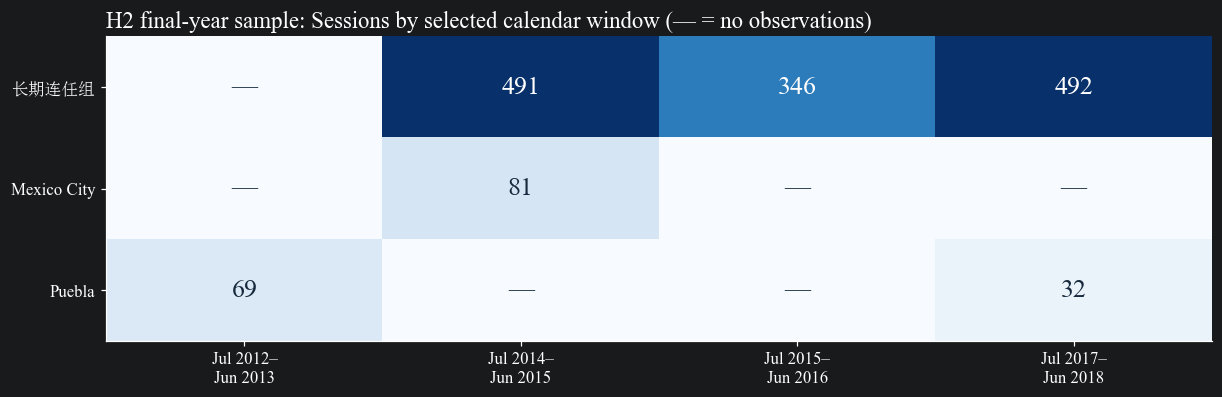

reform
0    80
1     1
Name: 会议数, dtype: int64

In [34]:
h2 = h2_designs['timingc'].frame.copy()
h2['D'] = h2.D_long
h2['L'] = h2.date2.between(20170007,20180006).astype(int)
h2['E'] = h2.date2.between(20120007,20130006).astype(int)
h2['P'] = h2.state.eq('Puebla').astype(int)
windows = [(20120007,20130006),(20140007,20150006),
           (20150007,20160006),(20170007,20180006)]
window_labels = ['Jul 2012–Jun 2013','Jul 2014–Jun 2015',
                 'Jul 2015–Jun 2016','Jul 2017–Jun 2018']
group_masks = [h2.treat4.eq(1),h2.state.eq('CdMex'),h2.state.eq('Puebla')]
coverage = pd.DataFrame([[int((mask & h2.date2.between(lo,hi)).sum())
                          for lo,hi in windows] for mask in group_masks],
                          index=['长期连任组','Mexico City','Puebla'],columns=window_labels)
assert coverage.to_numpy().tolist() == [[0,491,346,492],[0,81,0,0],[69,0,0,32]]
display(coverage)
fig, ax = plt.subplots(figsize=(11,3.5),layout='constrained')
ax.imshow(coverage, cmap='Blues', vmin=0, vmax=coverage.to_numpy().max(),aspect='auto')
for i in range(3):
    for j in range(4):
        n = int(coverage.iloc[i,j])
        ax.text(j,i,str(n) if n else '—',ha='center',va='center',fontsize=17,
                color='white' if n>300 else '#172A3D')
ax.set_xticks(range(4),[s.replace('–','–\n') for s in window_labels])
ax.set_yticks(range(3),coverage.index)
ax.set_title('H2 final-year sample: Sessions by selected calendar window (— = no observations)',loc='left')
plt.show()

cdmex_coding = h2.loc[h2.state.eq('CdMex')].groupby('reform').size().rename('会议数')
display(cdmex_coding)

末期只有普埃布拉提供限制连任组的对照观测，但他用于较早比较的记录在 2012/13，缺少中间窗口。墨西哥城虽然有2014/15，但缺2017/18。

### 4.3 对照正常 DID

这里计算的是**处理变量 D 的双重差分**，用于检查独立变化，对图示的标准两组、两期处理状态 $\begin{pmatrix}0&1\\0&0\end{pmatrix}$，有 $(1-0)-(0-0)=1$。

假设 $D_{st}=a_s+b_t$：$a_s$ 是同一州不随时间改变的组成部分，$b_t$ 是同一年月对各州共同的组成部分，则两组都只能变化 $b_1-b_0$，二者变化之差必然为0。正常双重差分给出1，故无法这样表示。但在原 H2 末年样本中，可以给出一套 $a_s,b_t$ 满足全部已有观测：长期连任组和墨西哥城的 $a_s=0$，普埃布拉的 $a_s=-1$；早期、末期的 $b_t=1$，中间窗口的 $b_t=0$。

In [35]:
S = np.array([1.,1.,0.,0.]); T = np.array([0.,1.,0.,1.]); D = S*T
F_standard = np.column_stack([np.ones(4),S,T])
standard_residual = D-F_standard@np.linalg.lstsq(F_standard,D,rcond=None)[0]
assert np.isclose(standard_residual@standard_residual,.25)
display(pd.DataFrame([
 {'比较':'标准2×2示例','FE秩':np.linalg.matrix_rank(F_standard),
  'FE+D秩':np.linalg.matrix_rank(np.column_stack([F_standard,D])),
  '残差化D平方和':standard_residual@standard_residual},
 {'比较':'原H2末年样本','FE秩':59,'FE+D秩':59,
  '残差化D平方和':h2_records[2]['residual_D_ss']}
]))

,比较,FE秩,FE+D秩,残差化D平方和
0,标准2×2示例,3,4,2.500000e-01
1,原H2末年样本,59,59,4.737308e-27


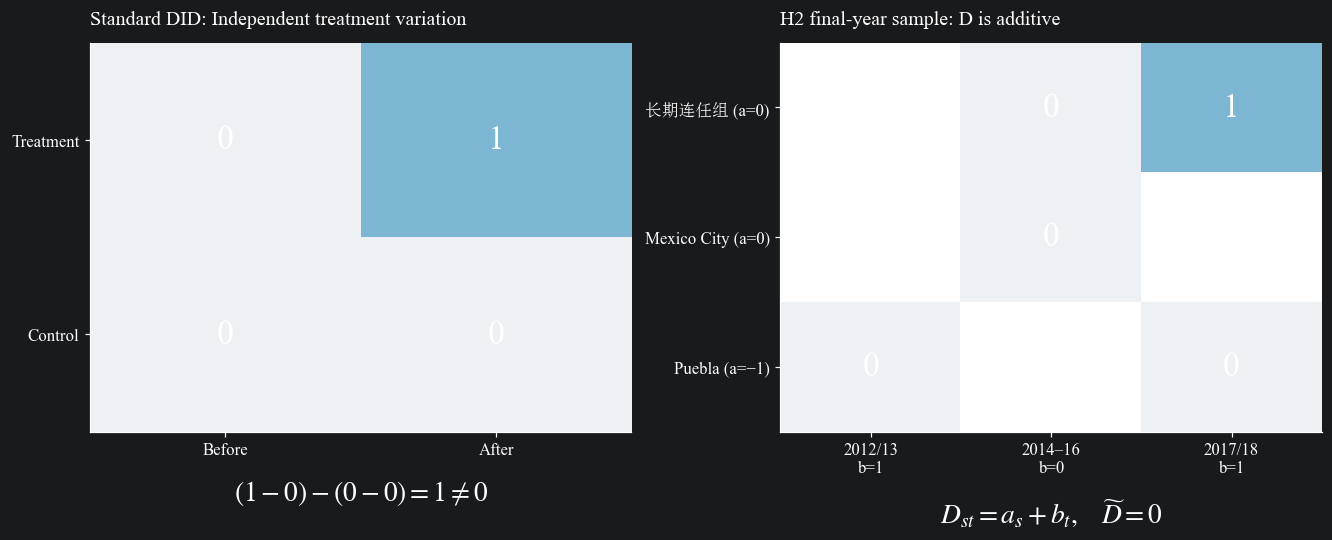

In [36]:
# 由本次运行的实际 h2 样本生成右图；缺失组合保持 NaN。
from matplotlib.colors import ListedColormap, BoundaryNorm
display_frame = h2.assign(
    display_group=np.select([h2.treat4.eq(1),h2.state.eq('CdMex')],
                            ['长期连任组','Mexico City'],default='Puebla'),
    calendar=np.select([h2.E.eq(1),h2.L.eq(1)],['2012/13','2017/18'],default='2014–16'))
assert display_frame.groupby(['display_group','calendar']).D.nunique().le(1).all()
observed_matrix = display_frame.pivot_table(index='display_group',columns='calendar',
                      values='D',aggfunc='first').reindex(
                      index=['长期连任组','Mexico City','Puebla'],
                      columns=['2012/13','2014–16','2017/18'])
assert np.array_equal(h2.D, -h2.P + (h2.L+h2.E))
cmap = ListedColormap(['#EDF1F4','#7CB6D3']); cmap.set_bad('#FFFFFF')
fig, axes = plt.subplots(1,2,figsize=(12,4.8),layout='constrained')
panels = [(np.array([[0.,1.],[0.,0.]]),['Treatment','Control'],['Before','After'],
           'Standard DID: Independent treatment variation'),
          (observed_matrix.to_numpy(),['长期连任组 (a=0)','Mexico City (a=0)','Puebla (a=−1)'],
           ['2012/13\nb=1','2014–16\nb=0','2017/18\nb=1'],
           'H2 final-year sample: D is additive')]
for ax, (values, row_names, column_names, title) in zip(axes,panels):
    ax.imshow(np.ma.masked_invalid(values),cmap=cmap,
              norm=BoundaryNorm([-.5,.5,1.5],2),aspect='auto')
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            val=values[i,j]
            ax.text(j,i,'—' if np.isnan(val) else str(int(val)),ha='center',va='center',fontsize=22)
    ax.set_xticks(range(len(column_names)),column_names)
    ax.set_yticks(range(len(row_names)),row_names)
    ax.set_title(title,loc='left',fontsize=13,pad=12)
axes[0].set_xlabel(r'$(1-0)-(0-0)=1\ne0$',fontsize=18,labelpad=13)
axes[1].set_xlabel(r'$D_{st}=a_s+b_t,\quad\widetilde D=0$',fontsize=18,labelpad=13)
plt.show()

### 4.4 逐行恒等式与矩阵秩

定义 $L_t$ 为2017年7月至2018年6月的时间窗口，$E_t$ 为2012年7月至2013年6月的时间窗口，$P_s$ 为普埃布拉指标。则在这个子样本中：

$$D_{st}=R_sT_{st}=L_t+E_t-P_s.$$

$L_t,E_t$ 可由年月虚拟变量表示，$P_s$ 可由州虚拟变量表示，因此 $D$ 属于固定效应项张成的空间。下面逐行核对并比较加入 D 前后的秩。

In [37]:
identity_error = h2.D - (h2.L+h2.E-h2.P)
assert (identity_error == 0).all()
identity_rows = h2.groupby(['group','reform','L','E','P'],dropna=False).agg(
    N=('D','size'),D=('D','first')).reset_index()
identity_rows['L+E-P'] = identity_rows.L+identity_rows.E-identity_rows.P
display(identity_rows)
display(pd.DataFrame([
    {'比较':'H1 整体样本','N':h1['n'],'FE秩':h1['rank_FE'],'FE+D秩':h1['rank_FE_D'],
     '残差化D平方和':h1['residual_D_ss']},
    {'比较':'H2 末年样本','N':len(h2),'FE秩':h2_records[2]['rank_FE'],
     'FE+D秩':h2_records[2]['rank_FE_D'],'残差化D平方和':h2_records[2]['residual_D_ss']}
]))

,group,reform,L,E,P,N,D,L+E-P
0,长期连任组,0,0,0,0,837,0.0,0
1,长期连任组,1,1,0,0,492,1.0,1
2,限制连任组,0,0,0,0,80,0.0,0
3,限制连任组,0,0,1,1,69,0.0,0
4,限制连任组,1,0,0,0,1,0.0,0
5,限制连任组,1,1,0,1,32,0.0,0


,比较,N,FE秩,FE+D秩,残差化D平方和
0,H1 整体样本,4899,102,103,2.621121e+02
1,H2 末年样本,1511,59,59,4.737308e-27


### 4.5 完全共线性

共同基准为2012年7月的Campeche。正常省略基准组后，固定效应矩阵已经满列秩；再保留 D 并额外省略一个中间日历窗口的月份项，就施加了额外约束。

按公开脚本的变量顺序重构时，保留截距、D、州项和升序年月项，2016 年 6 月成为冗余列。额外省略这一列可以复现图中的 +4.60 个百分点。因此，H2 末年样本中的双重差分处理项与地区、时间固定效应项**完全共线**。

In [38]:
def explicit_fe(frame, state_base=None, month_base=None):
    states = pd.get_dummies(frame.state, prefix='s', dtype=float)
    months = pd.get_dummies(frame.date2.astype(int), prefix='m', dtype=float)
    state_ref = states.columns[0] if state_base is None else f's_{state_base}'
    month_ref = months.columns[0] if month_base is None else f'm_{month_base}'
    const = pd.Series(1.0, index=frame.index, name='const')
    return pd.concat(
        [const, states.drop(columns=state_ref), months.drop(columns=month_ref)],
        axis=1,
    )


F_h2 = explicit_fe(h2)
d = h2.D.to_numpy(dtype=float)
assert np.linalg.matrix_rank(F_h2) == F_h2.shape[1] == 59

pure_fe = sm.OLS(h2.particularistic, F_h2).fit()

# D = F_h2 @ a，因此把 β 从 0 改为 b 时，FE 系数要减去 b*a。
a = np.linalg.lstsq(F_h2, d, rcond=None)[0]
np.testing.assert_allclose(F_h2 @ a, d, atol=1e-12, rtol=0)

# 换一套正常基准后，加入 D 仍不增加固定效应矩阵的秩。
for F in (F_h2, explicit_fe(h2, 'Puebla', 20140007)):
    rank_fe = np.linalg.matrix_rank(F)
    rank_full = np.linalg.matrix_rank(np.column_stack([F, d]))
    assert rank_fe == F.shape[1] == rank_full == 59

In [39]:
constrained_models = {}
allocation = {'纯固定效应': {'beta':np.nan, **pure_fe.params.to_dict()}}
for omitted, label in [(20160006,'额外省略2016年6月'),(20140007,'额外省略2014年7月')]:
    X = pd.concat([F_h2[['const']],h2.D.rename('D'),F_h2.drop(columns=['const',f'm_{omitted}'])],axis=1)
    assert np.linalg.matrix_rank(X) == X.shape[1] == 59
    fit = sm.OLS(h2.particularistic,X).fit(cov_type='cluster',
        cov_kwds={'groups':h2.state},use_t=True)
    constrained_models[label] = fit
    parameters = fit.params.to_dict()
    parameters[f'm_{omitted}'] = 0.
    parameters['beta'] = parameters.pop('D')
    allocation[label] = parameters
    assert np.max(np.abs(fit.fittedvalues-pure_fe.fittedvalues)) < 1e-12

coefficient_rows = [('β','beta'),('2016年6月 γ','m_20160006'),
                    ('2014年7月 γ','m_20140007'),('普埃布拉 μ','s_Puebla'),('截距 α','const')]
allocation_table = pd.DataFrame({name:{label:values.get(key,np.nan)*100
                      for label,key in coefficient_rows} for name,values in allocation.items()})
allocation_display = allocation_table.astype({'纯固定效应': object})
allocation_display.at['β', '纯固定效应'] = '未纳入'
display(allocation_display.rename_axis('参数（百分点）'))
constraint_inference = []
for label, fit in constrained_models.items():
    # 沿用同一聚类协方差和 t 分布，只计算 D 的标准误与 p 值。
    treatment_contrast = fit.t_test('D = 0')
    treatment_se = treatment_contrast.sd.item()
    assert np.isfinite(treatment_se) and treatment_se > 0
    constraint_inference.append({'额外约束':label,'β（百分点）':fit.params.D*100,
        'SE（百分点）':treatment_se*100,'p（约束下）':treatment_contrast.pvalue.item(),
        '与纯FE预测的最大差':np.abs(fit.fittedvalues-pure_fe.fittedvalues).max()})
display(pd.DataFrame(constraint_inference))
assert np.isclose(constrained_models['额外省略2016年6月'].params.D,.04599196022827533)
assert np.isclose(constrained_models['额外省略2014年7月'].params.D,.05577290025185785)

,纯固定效应,额外省略2016年6月,额外省略2014年7月
参数（百分点）,,,
β,未纳入,4.599196,5.577290
2016年6月 γ,-4.599196,0.000000,0.978094
2014年7月 γ,-5.57729,-0.978094,0.000000
普埃布拉 μ,-1.293707,3.305489,4.283583
截距 α,8.392851,3.793655,2.815561


,额外约束,β（百分点）,SE（百分点）,p（约束下）,与纯FE预测的最大差
0,额外省略2016年6月,4.599196,1.173797,0.001764,1.401657e-15
1,额外省略2014年7月,5.577290,0.683639,0.000002,9.714451e-16


In [40]:
# 按作者命令的列顺序重构，依次保留提供独立变化的列。
def redundant_fe_columns(matrix):
    basis, redundant = [], []
    for column in matrix.columns:
        residual = matrix[column].to_numpy(float).copy()
        for _ in range(2):  # 再正交化，降低浮点误差。
            for q in basis:
                residual -= q * (q @ residual)
        norm = np.linalg.norm(residual)
        if norm < 1e-8:
            redundant.append(column)
        else:
            basis.append(residual / norm)
    return redundant


candidate = pd.concat([F_h2[['const']], h2.D.rename('D'),
                       F_h2.drop(columns='const')], axis=1)
omitted_columns = redundant_fe_columns(candidate)
assert omitted_columns == ['m_20160006']
print('顺序重构的额外冗余列：', omitted_columns)

顺序重构的额外冗余列： ['m_20160006']


Stata 复跑核验。 我们使用作者公开的 allres.csv，沿用 replication_analysis.do 中的数据处理和 timingc 样本筛选，在 Stata/MP 19.5 中执行 Figure 6 的末年回归。

```stata
reg particularistic timb3 i.edo i.date2 if timingc==1, robust cluster(edo)
```

Stata 在回归表之前打印了这条提示。

```text
note: 20160006.date2 omitted because of collinearity.
```

回归表中，2016 年 6 月的年月固定效应项显示为 0 (omitted)。Stata 保留了处理项 timb3，报告系数为 0.04599196，即 +4.60 个百分点，州聚类标准误为 1.17 个百分点。这一结果与上面 Python 重建得到的冗余列一致。在本次复跑中，省略 2016 年 6 月是 Stata 自动作出的选择。 下文推导这个省略约束如何决定 timb3 的系数。

**$\beta$ 与 2016 年 6 月固定效应项系数相反的原因**

代入后的原模型：

$$Y=\alpha+[\gamma_t+\beta(L_t+E_t)]+[\mu_s-\beta P_s]+\varepsilon$$

纯固定效应模型：

$$Y=\alpha^{FE}+\gamma_t^{FE}+\mu_s^{FE}+\varepsilon^{FE}$$

**对齐两套参数化**：个体项 $\mu_s-\beta P_s$ 与 $\mu_s^{FE}$ 都只随 $s$ 变动，
其差可并入个体效应，记作常数 $c$。于是时间部分须逐期相等：

$$\alpha+\gamma_t+\beta(L_t+E_t)=\alpha^{FE}+\gamma_t^{FE}+c \tag{1}$$

取基准期 $t_0$，令两套参数化在该期的时间效应均为零，
即 $\gamma_{t_0}=0$、$\gamma^{FE}_{t_0}=0$。(1) 在 $t_0$ 处化为：

$$\alpha+\beta(L_{t_0}+E_{t_0})=\alpha^{FE}+c \tag{2}$$

(1) 减 (2)：

$$\gamma^{FE}_t=\gamma_t+\beta\big[(L_t+E_t)-(L_{t_0}+E_{t_0})\big] \tag{3}$$

**基准期的窗口归属决定常数项。** 若 $t_0$ 落在早期窗口内，
则 $L_{t_0}+E_{t_0}=1$，(3) 化为：

$$\gamma^{FE}_t=\gamma_t+\beta\big[(L_t+E_t)-1\big] \tag{4}$$

对窗口外且 $\gamma_t=0$ 的月份（如 2016 年 6 月），$(L_t+E_t)=0$，(4) 化为

$$\gamma^{FE}_t=-\beta$$

代入估计值 $\gamma^{FE}_{2016.6}=-0.04599196$，得

$$\beta=+0.04599196\quad\text{（约 +4.60 个百分点）}$$

原始模型的 $\beta$ 被窗口指示项同时"用"了两次：
一次进入处理效应，一次被吸进时间固定效应。
基准期自带窗口项时，整套时间固定效应须整体下移 $\beta$ 才能与原参数化对齐，
于是窗口外月份的 FE 系数恰好等于 $-\beta$。

### 4.6 重建图 6：同一拟合如何产生不同的末期点

**先看逐场拟合值。** 在 H2 末年样本中，$D=Fa$。任意指定 $\beta$ 后，把纯固定效应系数 $\widehat{\theta}$ 调整为 $\widehat{\theta}-\beta a$。对任意一场会议 $i$，处理项的增量被固定效应抵消：

$$\widehat Y_i(\beta)=F_i(\widehat{\theta}-\beta a)+\beta D_i=F_i\widehat{\theta}.$$

左图用一场 $D=1$ 的会议展示两部分如何抵消。右图用 $-10$、$0$、$+4.60$ 和 $+10$ 个百分点四组指定值，逐场对照同一批 1,511 场会议的拟合值。

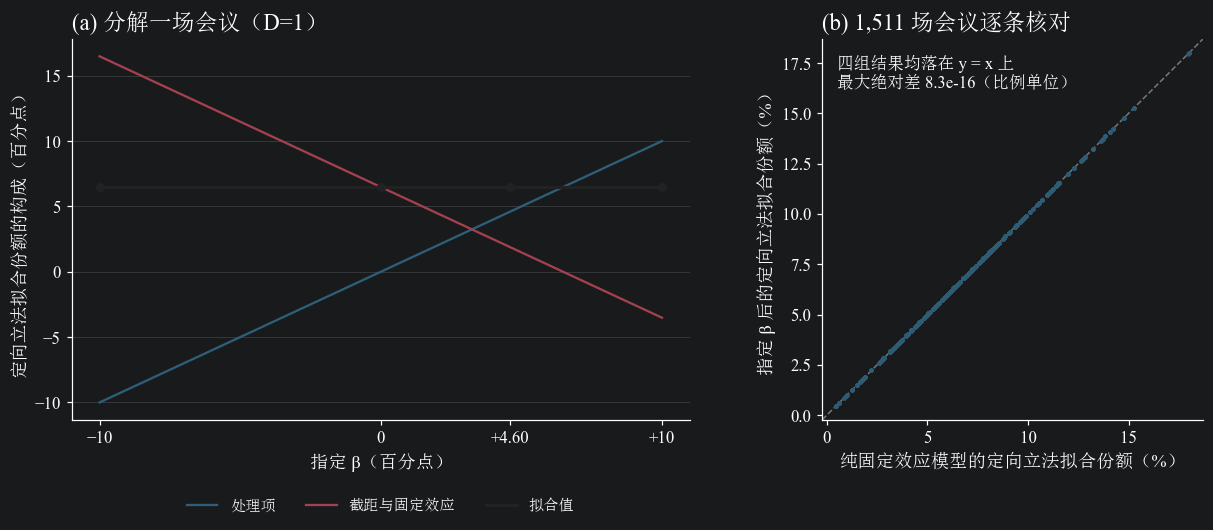

In [41]:
june_beta = constrained_models['额外省略2016年6月'].params.D
beta_pp = np.array([-10.0, 0.0, 100 * june_beta, 10.0])
fe_matrix = F_h2.to_numpy()
fe_estimate = pure_fe.params.to_numpy()
reference_fit = pure_fe.fittedvalues.to_numpy()
treatment = h2.D.to_numpy(dtype=float)

# 四个指定 β 各对应一列，每行始终是同一场会议。
beta_values = beta_pp / 100
adjusted_fe = fe_estimate[:, None] - a[:, None] * beta_values
all_fits = fe_matrix @ adjusted_fe + treatment[:, None] * beta_values
max_fit_gap = float(np.max(np.abs(all_fits - reference_fit[:, None])))
assert max_fit_gap < 1e-12

# 在 D=1 的会议中选取基准拟合值最接近组内中位数的一场。
treated_rows = np.flatnonzero(treatment == 1)
fit_median = np.median(reference_fit[treated_rows])
row = treated_rows[np.argmin(np.abs(reference_fit[treated_rows] - fit_median))]
beta_grid = np.linspace(beta_pp.min(), beta_pp.max(), 101)
treatment_part = treatment[row] * beta_grid
fe_part = 100 * (fe_matrix[row] @ (fe_estimate[:, None] - a[:, None] * beta_grid / 100))

fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.7), layout='constrained')
left.plot(beta_grid, treatment_part, color='#2E5F7A', label='处理项')
left.plot(beta_grid, fe_part, color='#A34150', label='截距与固定效应')
left.plot(beta_grid, treatment_part + fe_part, color='#222222', linewidth=2.1, label='拟合值')
left.scatter(beta_pp, 100 * all_fits[row], color='#222222', s=25, zorder=3)
left.set_xticks(beta_pp, ['−10', '0', '+4.60', '+10'])
left.set(xlabel='指定 β（百分点）', ylabel='定向立法拟合份额的构成（百分点）')
left.set_title('(a) 分解一场会议（D=1）', loc='left')
left.grid(axis='y', alpha=0.25)
left.legend(loc='upper center', bbox_to_anchor=(0.5, -0.17), ncol=3, frameon=False)

limits = [100 * min(reference_fit.min(), all_fits.min()),
          100 * max(reference_fit.max(), all_fits.max())]
margin = 0.04 * (limits[1] - limits[0])
limits = [limits[0] - margin, limits[1] + margin]
right.plot(limits, limits, color='#777777', linestyle='--', linewidth=1, zorder=1)
right.scatter(100 * np.repeat(reference_fit, len(beta_pp)), 100 * all_fits.ravel(),
              color='#2E5F7A', alpha=0.3, s=9, linewidths=0, zorder=2)
right.set(xlim=limits, ylim=limits, xlabel='纯固定效应模型的定向立法拟合份额（%）',
          ylabel='指定 β 后的定向立法拟合份额（%）')
right.set_aspect('equal', adjustable='box')
right.set_title(f'(b) {len(h2):,} 场会议逐条核对', loc='left')
right.text(0.04, 0.96, f'四组结果均落在 y = x 上\n最大绝对差 {max_fit_gap:.1e}（比例单位）',
           transform=right.transAxes, va='top', fontsize=11)
plt.show()

**按公开脚本重建。** 作者分别对 `timinga`、`timingb`、`timingc` 三个样本运行以下回归，并绘制 90% 和 95% 聚类置信区间：

```stata
reg particularistic timb3 i.edo i.date2 if timingc==1, robust cluster(edo)
```

下方将三个回归翻译为 Python，末期按 4.5 的顺序保留独立列，额外省略 2016 年 6 月，重现图中的 $+4.60$ 个百分点。

**从固定效应的线性组合重建。** 令 $F$ 为包含截距的固定效应矩阵，$D=Fa$，$\widehat{\theta}$ 为纯固定效应模型的系数。给定任意 $\beta$，把固定效应系数改为 $\widehat{\theta}-\beta a$，拟合值仍是 $F\widehat{\theta}$。若额外约束月份 $m$ 相对于原基准月 $t_0$ 的系数差为零，用 $c$ 表示取这两个系数之差的向量，则：

$$c^\top(\widehat{\theta}-\beta a)=0
\quad\Longrightarrow\quad
\widehat{\beta}=\frac{c^\top\widehat{\theta}}{c^\top a}.$$

原基准月为 2012 年 7 月时，$m=\text{2016 年 6 月}$ 的分母为 $-1$，于是 $\widehat{\beta}=-\widehat{\gamma}^{FE}_{2016.6}$。若把纯固定效应回归改用另一基准月，同一数量等于 $\widehat{\gamma}^{FE}_{2012.7}-\widehat{\gamma}^{FE}_{2016.6}$。下面用这两个线性组合独立重现图 6 的末期点和置信区间，再分别将约束月改为 2014 年 7 月和 2015 年 1 月作对照。

In [42]:
def fit_figure6_ols(frame, matrix):
    return sm.OLS(frame.particularistic, matrix).fit(
        cov_type='cluster', cov_kwds={'groups': frame.state}, use_t=True)


def figure6_inference(fit, contrast):
    test = fit.t_test(contrast)
    return {'beta': test.effect.item(), 'se': test.sd.item(),
            'df': fit.df_resid_inference}


# 翻译作者的三条回归。末期沿用 4.5 的顺序选列重构。
figure6_stata = {}
for period in ('timinga', 'timingb', 'timingc'):
    frame = h2_designs[period].frame
    fe = explicit_fe(frame)
    design = pd.concat([fe[['const']], frame.D_long.rename('D'),
                        fe.drop(columns='const')], axis=1)
    redundant = redundant_fe_columns(design)
    if period == 'timingc':
        assert redundant == omitted_columns
    assert 'D' not in redundant
    design = design.drop(columns=redundant)
    assert np.linalg.matrix_rank(design) == design.shape[1]
    figure6_stata[period] = fit_figure6_ols(frame, design)

figure6_reconstructed = [figure6_inference(fit, 'D = 0')
                         for fit in figure6_stata.values()]
for result, check in zip(figure6_reconstructed[:2], h2_records[:2]):
    np.testing.assert_allclose([result['beta'], result['se']],
                               [check['b'], check['se']], atol=1e-12, rtol=0)


def figure6_from_fe(fe, omitted_month):
    fit = fit_figure6_ols(h2, fe)
    d_as_fe = np.linalg.lstsq(fe, h2.D, rcond=None)[0]
    np.testing.assert_allclose(fe @ d_as_fe, h2.D, atol=1e-12, rtol=0)

    # c 取额外约束月与原基准月的系数差。当前编码省略的基准月自动记作零。
    c = np.array([int(col == f'm_{omitted_month}') - int(col == 'm_20120007')
                  for col in fe.columns], dtype=float)
    denominator = c @ d_as_fe
    assert np.isclose(denominator, -1.0)
    result = figure6_inference(fit, c / denominator)
    shifted_fe = fit.params.to_numpy() - result['beta'] * d_as_fe
    prediction = fe @ shifted_fe + result['beta'] * h2.D
    assert np.isclose(c @ shifted_fe, 0.0, atol=1e-12)
    return result, prediction


june_drop = constrained_models['额外省略2016年6月']
july_drop = constrained_models['额外省略2014年7月']
june_fe, june_prediction = figure6_from_fe(F_h2, 20160006)
june_rebased, rebased_prediction = figure6_from_fe(
    explicit_fe(h2, 'Puebla', 20140007), 20160006)
july_fe, july_prediction = figure6_from_fe(F_h2, 20140007)
january_fe, january_prediction = figure6_from_fe(F_h2, 20150001)

figure6_comparisons = [
    ('按原文代码复现', figure6_reconstructed[-1], figure6_stata['timingc'].fittedvalues),
    ('保留 D，省略 2016 年 6 月', figure6_inference(june_drop, 'D = 0'), june_drop.fittedvalues),
    ('纯固定效应：保留2016 年 6 月', june_fe, june_prediction),
    ('换基准后：保留2016 年 6 月', june_rebased, rebased_prediction),
    ('改约束月为 2014 年 7 月', july_fe, july_prediction),
    ('改约束月为 2015 年 1 月', january_fe, january_prediction),
]
for _, result, prediction in figure6_comparisons:
    np.testing.assert_allclose(prediction, pure_fe.fittedvalues, atol=1e-12, rtol=0)
    assert result['df'] == 13
reference = [figure6_reconstructed[-1]['beta'], figure6_reconstructed[-1]['se']]
for _, result, _ in figure6_comparisons[:4]:
    np.testing.assert_allclose([result['beta'], result['se']], reference, atol=1e-12, rtol=0)
july_check = figure6_inference(july_drop, 'D = 0')
np.testing.assert_allclose([july_fe['beta'], july_fe['se']],
                           [july_check['beta'], july_check['se']], atol=1e-12, rtol=0)

january_design = F_h2.drop(columns='m_20150001').assign(D=h2.D)
assert np.linalg.matrix_rank(january_design) == january_design.shape[1] == 59
january_drop = fit_figure6_ols(h2, january_design)
january_check = figure6_inference(january_drop, 'D = 0')
np.testing.assert_allclose([january_fe['beta'], january_fe['se']],
                           [january_check['beta'], january_check['se']], atol=1e-12, rtol=0)
np.testing.assert_allclose(january_drop.fittedvalues, pure_fe.fittedvalues, atol=1e-12, rtol=0)

display(pd.DataFrame([
    {'面板': f'({letter})', '末期参数化': label, '系数（百分点）': 100 * result['beta'],
     '聚类 SE（百分点）': 100 * result['se'],
     '与纯固定效应拟合值的最大差': np.max(np.abs(prediction - pure_fe.fittedvalues))}
    for letter, (label, result, prediction) in zip('abcdef', figure6_comparisons, strict=True)
]))

,面板,末期参数化,系数（百分点）,聚类 SE（百分点）,与纯固定效应拟合值的最大差
0,(a),按原文代码复现,4.599196,1.173797,1.401657e-15
1,(b),保留 D，省略 2016 年 6 月,4.599196,1.173797,1.401657e-15
2,(c),纯固定效应：保留2016 年 6 月,4.599196,1.173797,3.747003e-16
3,(d),换基准后：保留2016 年 6 月,4.599196,1.173797,1.554312e-15
4,(e),改约束月为 2014 年 7 月,5.577290,0.683639,4.614364e-16
5,(f),改约束月为 2015 年 1 月,5.733713,0.644913,4.718448e-16


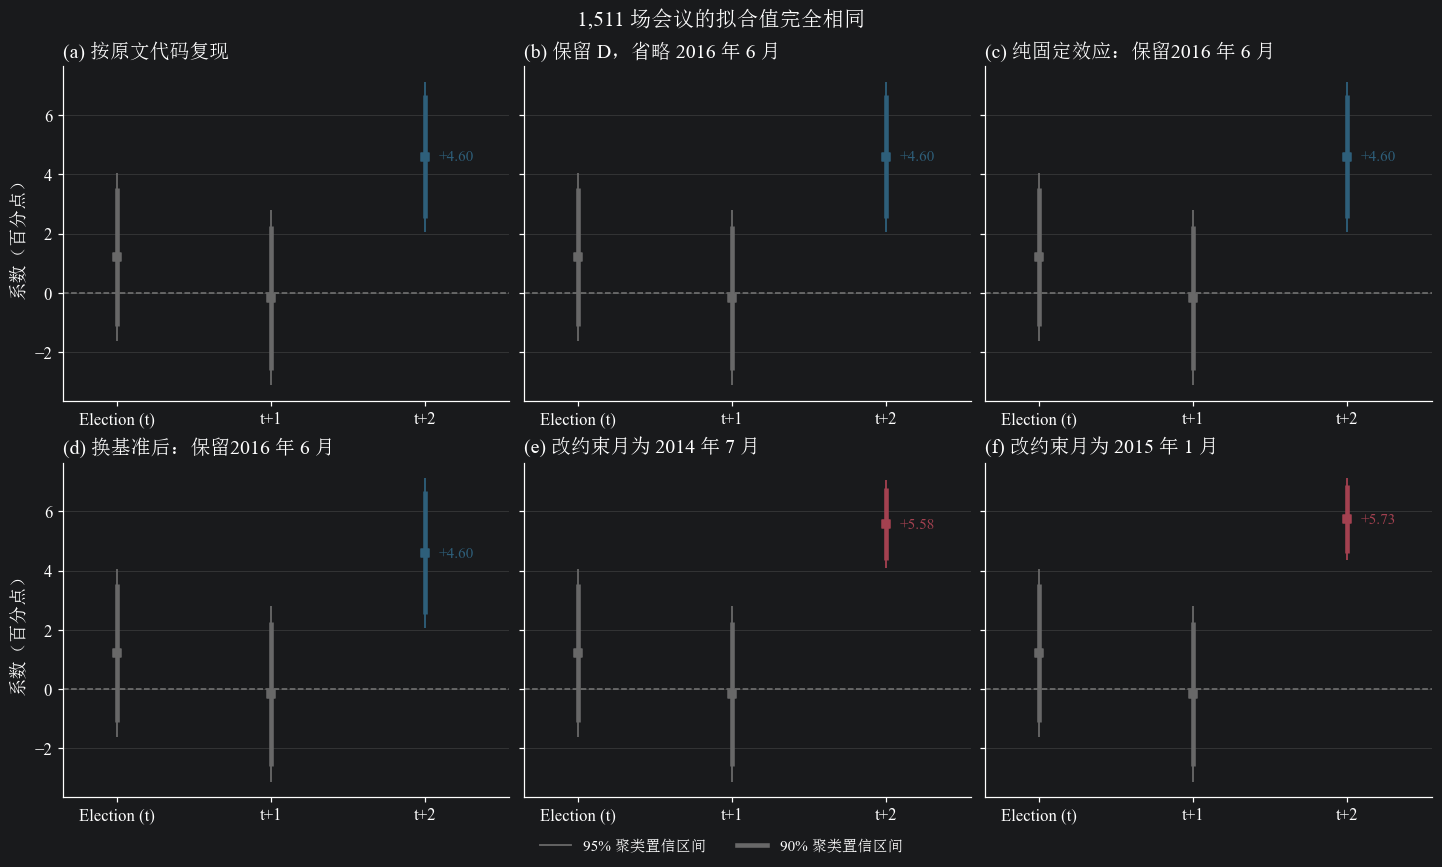

In [43]:
from matplotlib.lines import Line2D

fig, axes = plt.subplots(2, 3, figsize=(13, 7.8), sharey=True, layout='constrained')
max_comparison_gap = max(float(np.max(np.abs(prediction - pure_fe.fittedvalues)))
                         for _, _, prediction in figure6_comparisons)
assert max_comparison_gap < 1e-12
fig.suptitle(f'1,511 场会议的拟合值完全相同',
             fontsize=14)
for i, (ax, (label, last, _)) in enumerate(zip(axes.flat, figure6_comparisons, strict=True)):
    title = f'({chr(97 + i)}) {label}'
    last_color = '#2E5F7A' if i < 4 else '#A34150'
    ax.axhline(0, color='#777777', linestyle='--', linewidth=1)
    for position, result in enumerate([*figure6_reconstructed[:2], last]):
        estimate = 100 * result['beta']
        se = 100 * result['se']
        color = last_color if position == 2 else '#686868'
        for confidence, width in [(0.95, 1.2), (0.90, 3.0)]:
            half_width = student_t.ppf((1 + confidence) / 2, result['df']) * se
            ax.vlines(position, estimate - half_width, estimate + half_width,
                      color=color, linewidth=width)
        ax.scatter(position, estimate, color=color, marker='s', zorder=3, s=34)
    ax.annotate(f'{100 * last["beta"]:+.2f}', (2, 100 * last['beta']),
                xytext=(9, 0), textcoords='offset points', va='center', color=last_color)
    ax.set_xticks([0, 1, 2], ['Election (t)', 't+1', 't+2'])
    ax.set_xlim(-0.35, 2.55)
    ax.set_title(title, loc='left', fontsize=13)
    ax.grid(axis='y', alpha=0.22)
for ax in axes[:, 0]:
    ax.set_ylabel('系数（百分点）')
fig.legend(handles=[Line2D([0], [0], color='#686868', linewidth=1.2, label='95% 聚类置信区间'),
                    Line2D([0], [0], color='#686868', linewidth=3.0, label='90% 聚类置信区间')],
           loc='outside lower center', ncol=2, frameon=False)
plt.show()

图 (a) 至 (d) 以不同方式重现同一个末期点 **+4.60 个百分点**，图 (d) 把纯固定效应回归的基准月换成 2014 年 7 月。图 (e) 和 (f) 分别改用 2014 年 7 月和 2015 年 1 月作为额外约束，末期的系数和区间随之改变。六个面板对末期 1,511 场会议的拟合值在浮点精度内完全相同。面板和表格按 (a) 至 (f) 一一对应。

### 4.7 补回缺失数据

完全共线的原因是缺乏数据，作为限制连任组的唯二地区，墨西哥城和普爱布拉都缺乏数据，补回缺失数据后能打破完全共线性。

In [44]:
def rank_check(frame):
    X = explicit_fe(frame)
    return int(np.linalg.matrix_rank(X)), int(np.linalg.matrix_rank(np.column_stack([X,frame.D])))

minimal = h2[['state','date2','D']].copy()
hypothetical = pd.concat([minimal,pd.DataFrame([{'state':'CdMex','date2':20170007,'D':0.}])],ignore_index=True)
puebla_actual = data.loc[data.state.eq('Puebla') & data.date2.eq(20140007)].copy()
puebla_actual['D'] = puebla_actual.D_long
assert len(puebla_actual) == 5 and puebla_actual.D.eq(0).all()
restored = pd.concat([minimal,puebla_actual[['state','date2','D']]],ignore_index=True)
checks = [
    {'样本':'原 H2 末年样本','N':len(minimal),'新增记录类型':'无','FE秩':rank_check(minimal)[0],'FE+D秩':rank_check(minimal)[1]},
    {'样本':'加入墨西哥城2017年7月','N':len(hypothetical),'新增记录类型':'1 条假设记录，',
     'FE秩':rank_check(hypothetical)[0],'FE+D秩':rank_check(hypothetical)[1]},
    {'样本':'补回普埃布拉2014年7月','N':len(restored),'新增记录类型':'5 条真实记录',
     'FE秩':rank_check(restored)[0],'FE+D秩':rank_check(restored)[1]}
]
assert rank_check(hypothetical)==(59,60) and rank_check(restored)==(59,60)
display(pd.DataFrame(checks))
display(pd.DataFrame([
 {'新增单元':'墨西哥城2017年7月（假设）','R×T':0,'L+E-P':1},
 {'新增单元':'普埃布拉2014年7月（真实）','R×T':0,'L+E-P':-1}]))

,样本,N,新增记录类型,FE秩,FE+D秩
0,原 H2 末年样本,1511,无,59,59
1,加入墨西哥城2017年7月,1512,1 条假设记录，,59,60
2,补回普埃布拉2014年7月,1516,5 条真实记录,59,60


,新增单元,R×T,L+E-P
0,墨西哥城2017年7月（假设）,0,1
1,普埃布拉2014年7月（真实）,0,-1


**H2 勘误结论**：在原脚本实际保留的1511条记录上，D可以由固定效应精确表示，也就是完全共线；正常设定基准组后，再加D不增加矩阵秩。改变β并相应调整固定效应，预测不变。因此我们质疑原文 Figure 6 的末年估计在所述完整规格下的独立识别。

<a id="section-5"></a>

## 5. 补充分析：短期连任组与限制连任组

原文 Table 2 比较长期连任组与限制连任组，Table 3 比较长期连任组与短期连任组，但未估计短期连任组与限制连任组的差异。但按照 H1，应该比较。而我们的比较结果，质疑了原文假设。

以 `treat2 × reform` 为处理项，沿用原始编码、州和年月固定效应。样本含短期连任组的 6 个州和限制连任组的 2 个地区，共8个聚类；少聚类和对照来源少都影响推断，不能只说“有6个州”。

### 5.1 点估计、少聚类推断与对照地区剔除

,比较,会议数,州数,独立识别,估计（百分点）,聚类SE（百分点）,95%下限,95%上限,常规p,wild bootstrap p,rank_FE,rank_FE_D
0,完整样本,2807,8,True,-1.959779,0.404356,-2.915930,-1.003628,0.001863,0.06250,99,100
1,剔除墨西哥城,2415,7,True,-1.676525,0.597951,-3.139658,-0.213393,0.031009,0.28125,98,99
2,剔除普埃布拉,2377,7,True,-1.746367,0.602036,-3.219495,-0.273239,0.027307,0.21875,79,80


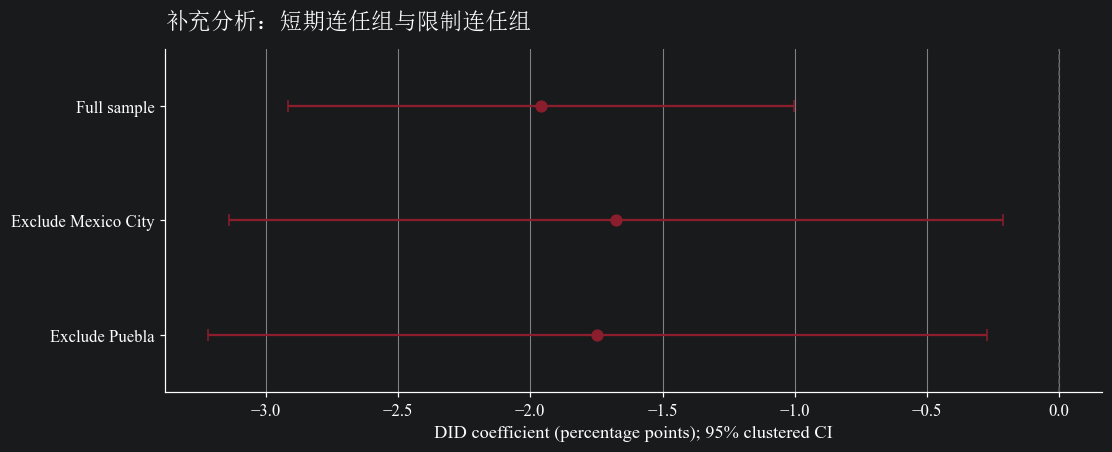

In [45]:
short_results = []
for label, excluded in [('完整样本',None),('剔除墨西哥城','CdMex'),('剔除普埃布拉','Puebla')]:
    frame = data.loc[data.D_short.notna()].copy()
    if excluded:
        frame = frame.loc[frame.state.ne(excluded)]
    model = FixedEffectsDesign(frame)
    r = model.fit('D_short', wild=True)
    r['comparison'] = label
    short_results.append(r)
assert short_results[0]['n'] == 2807
assert np.isclose(short_results[0]['b'], -.019597792144748865)
assert short_results[0]['wild_p'] == .0625
display(result_table(short_results))
fig, ax = plt.subplots(figsize=(10,4),layout='constrained')
forest(ax, short_results, ['Full sample','Exclude Mexico City','Exclude Puebla'],
       '补充分析：短期连任组与限制连任组', [COLORS['short']]*3)
plt.show()

完整样本的点估计约 **−1.96个百分点**。常规州聚类p值约0.0019，枚举wild cluster bootstrap p值为 **0.0625**；剔除任一对照地区后，bootstrap证据更弱。

### 5.2 处理前切点与多重比较

沿用相同33个切点，仅使用改革前记录。若每次检验都具有正确的5%误报率，在全部零假设成立时，预期显著数为33×0.05=1.65。

下面采用保留共同州顺序与权重的联合bootstrap，检验最大绝对t统计量。

,切点数,常规显著个数,联合max-|t| bootstrap p
0,33,6,0.117188


,切点序号,年份前移,月份,系数（比例单位）,聚类SE,常规p,bootstrap p
0,1,2,1,-0.020862,0.016993,0.259245,0.484375
1,2,2,2,-0.014771,0.015996,0.386510,0.484375
2,3,2,3,-0.007618,0.017749,0.680660,0.804688
3,4,2,4,-0.005658,0.014956,0.716385,0.812500
4,5,2,5,-0.009563,0.011230,0.422651,0.453125
5,6,2,6,-0.009693,0.012878,0.476180,0.656250
6,7,2,7,-0.013772,0.016447,0.430068,0.664062
7,8,2,8,-0.015902,0.015146,0.328651,0.554688
8,9,2,9,-0.017421,0.014158,0.258266,0.460938
9,10,2,10,-0.013004,0.013097,0.353830,0.562500


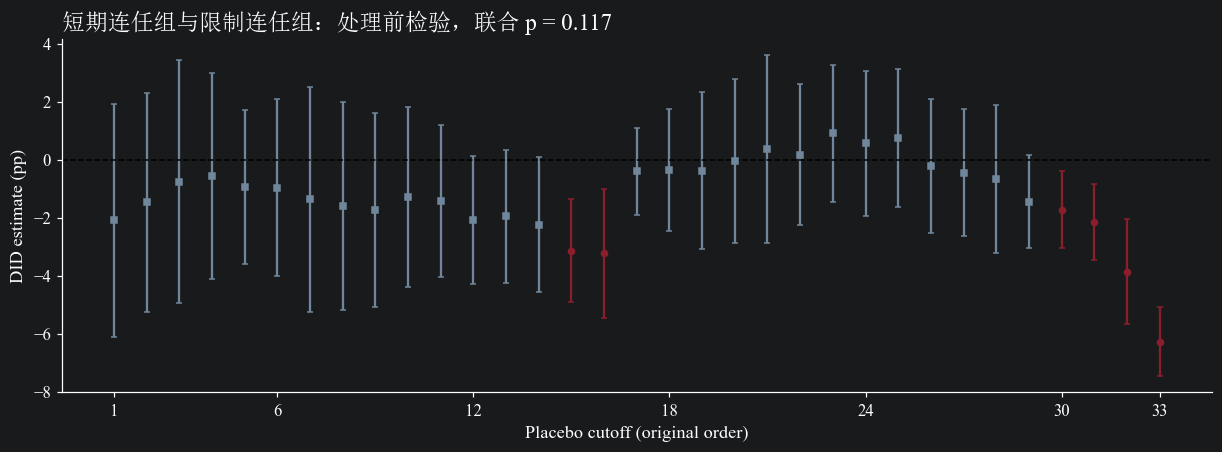

In [46]:
short_placebos, short_joint_p = placebo_checks('treat2', wild=True)
significant = short_placebos.p.lt(.05)
assert len(short_placebos) == 33 and significant.sum() == 6
assert (short_placebos.loc[significant,'b'] < 0).all()
assert np.isclose(short_joint_p, .1171875)
display(pd.DataFrame({'切点数':[33], '常规显著个数':[int(significant.sum())],
                       '联合max-|t| bootstrap p':[short_joint_p]}))
display(short_placebos[['cutoff','cohort_shift','month','b','se','p','wild_p']].rename(
    columns={'cutoff':'切点序号','cohort_shift':'年份前移','month':'月份',
             'b':'系数（比例单位）','se':'聚类SE','p':'常规p','wild_p':'bootstrap p'}))
fig, ax = plt.subplots(figsize=(11,4),layout='constrained')
for _, row in short_placebos.iterrows():
    color = COLORS['short'] if row.p < .05 else COLORS['muted']
    ax.errorbar(row.cutoff,row.b*100,
        yerr=[[100*(row.b-row.ci_lower)],[100*(row.ci_upper-row.b)]],
        fmt='o' if row.p<.05 else 's',ms=4,capsize=2,color=color)
ax.axhline(0,color='black',ls='--',lw=1)
ax.set(xlabel='Placebo cutoff (original order)',ylabel='DID estimate (pp)',
       xticks=[1,6,12,18,24,30,33])
ax.set_title(f'短期连任组与限制连任组：处理前检验，联合 p = {short_joint_p:.3f}',loc='left')
plt.show()

双重差分要求平行趋势假设成立，原文H1、H3的负效应之所以影响不大，是因为他们只会把真实正系数下拉，而让识别到的正系数证据更强。不过在短期连任组与限制连任组的比较中，因为主效应就是负数，所以平行趋势假设需要更严格，虽然不能证明错误，但也有力质疑了原文假设。

至于我们怀疑的选择性报告，不仅正文未报告短期连任组与限制连任组的比较，公开脚本中也未找到对应代码：在 replication_analysis.do 与 replication_appendix.do 中检索 treat2，仅发现其出现在 H3 的交互项 c.treat42#c.reform 中，未发现 treat2×reform 的单独回归。所以我们不清楚作者为什么没做。